## Problem 1:
Scenario:
A data scientist writes the following code:

from sklearn.impute import SimpleImputer   
from sklearn.model_selection import train_test_split  

df = pd.read_csv('data.csv')   
imputer = SimpleImputer(strategy='median')  
df[['Age', 'Salary']] = imputer.fit_transform(df[['Age', 'Salary']])  
X = df.drop('Target', axis=1)  
y = df['Target']  
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)  


Question: Identify the data leakage issue. Explain why it is wrong and write the corrected code.


## Answer :

এখানে train_test_split() করার আগেই পুরো ডেটাসেট (df) এর ওপর SimpleImputer ফিট (fit_transform) করা হয়েছে।

কেন এটি ভুল? (Why it is wrong)
১. Test Data-র তথ্য জেনে ফেলা (Information Leakage):
মিডিয়ান (Median) হিসাব করার সময় SimpleImputer পুরো ডেটাসেটের (Train এবং Test দুটো মিলে) মান ব্যবহার করেছে। ফলে Train সেট ইম্পুট করার সময় Test সেটের মান বা ডিস্ট্রিবিউশন সম্পর্কে আগেই জেনে যাচ্ছে।

২. Overfitting ও ভুল Evaluation Metric:
বাস্তব ক্ষেত্রে (Production Environment) যখন সম্পূর্ণ নতুন আনসিন ডেটা (Unseen Test Data) আসবে, তখন মডেলের এক্যুরেসি বা পারফরম্যান্স আশানুরূপ হবে না। কারণ মডেলটি এমন তথ্যের ওপর ট্রেন হয়েছে যা আগে থেকেই টেস্ট ডেটার গড়ের দ্বারা প্রভাবিত।

৩. সঠিক নিয়ম:
সবসময় ডেটা আগে Train এবং Test সেটে ভাগ (Split) করতে হয়। এরপর শুধুমাত্র X_train-এর ওপর ভিত্তি করে fit_transform() এবং X_test-এর ওপর শুধুমাত্র transform() প্রয়োগ করতে হয়।

## Correct Code :

In [134]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

df = pd.read_csv('data.csv')

X = df.drop(['Target'], axis= 1)
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state= 42)

imputer = SimpleImputer(strategy= 'median')


cols = ['Age', 'Salary']
X_train[cols] = imputer.fit_transform(X_train[cols])

X_test[cols] = imputer.transform(X_test[cols])

## Problem 2:
Question: Using the provided data.csv file, write code to find:
1. Total missing values in each column
2. Percentage of missing values per column
3. Which columns have more than 50% missing values?


In [135]:
df.isnull().sum()

Age                       180
Income                    150
Salary                      0
Rating                     80
Annual_Income             120
Customer_Support_Calls     80
House_Price               100
Square_Feet                 0
Temperature                50
City                       50
Product_Type                0
Location                    0
Diagnosis                 220
Cabin                     680
Embarked                    2
Gender                      0
Target                      0
Price_Target                0
dtype: int64

In [136]:
(df.isnull().sum() / len(df)) * 100  # length use kore missing value percentage ber korci

Age                       18.0
Income                    15.0
Salary                     0.0
Rating                     8.0
Annual_Income             12.0
Customer_Support_Calls     8.0
House_Price               10.0
Square_Feet                0.0
Temperature                5.0
City                       5.0
Product_Type               0.0
Location                   0.0
Diagnosis                 22.0
Cabin                     68.0
Embarked                   0.2
Gender                     0.0
Target                     0.0
Price_Target               0.0
dtype: float64

In [137]:
missing_per = df.isnull().mean()  * 100  # Another option mean use kore missing value percentage ber korci

In [138]:
col_50_perc_missing = missing_per[missing_per > 50]

col_50_perc_missing

Cabin    68.0
dtype: float64

## Problem 3:
Question: Look at the Temperature column in data.csv. It contains:

Numeric values like 22.5, 18.6  
String 'Unknown'  
NaN values  
Write code to handle this column properly before imputation.


In [139]:
import numpy as np

df['Temperature'] = pd.to_numeric(df['Temperature'].replace('Unknown', np.nan), errors= 'coerce' )



In [140]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     820 non-null    float64
 1   Income                  850 non-null    float64
 2   Salary                  1000 non-null   int64  
 3   Rating                  920 non-null    float64
 4   Annual_Income           880 non-null    float64
 5   Customer_Support_Calls  920 non-null    float64
 6   House_Price             900 non-null    float64
 7   Square_Feet             1000 non-null   int64  
 8   Temperature             885 non-null    float64
 9   City                    950 non-null    object 
 10  Product_Type            1000 non-null   object 
 11  Location                1000 non-null   object 
 12  Diagnosis               780 non-null    object 
 13  Cabin                   320 non-null    object 
 14  Embarked                998 non-null    o

## Problem 4:
Question: For the Diagnosis column in data.csv, implement imputation with:  
Constant strategy using 'Missing' string  
Add a missing indicator column  

Write the complete code using SimpleImputer.


In [141]:
imputer = SimpleImputer(strategy='constant', fill_value= 'Missing', add_indicator= True)


df[['Diagnosis', 'Diagonis_missing_indicator']] = imputer.fit_transform(df[['Diagnosis']])
df.head(3)


,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target,Diagonis_missing_indicator
0,40.0,9165.0,55361,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,Missing,NaN,S,Male,0,280.32,True
1,33.0,5522.0,48717,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,1,314.83,False
2,42.0,50589.0,64787,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,0,252.43,False


## Problem 5:
Question: Using the Age column from data.csv:  
1. Calculate mean and median from training data only
2. Create two new columns: Age_mean_imputed and Age_median_imputed
3. Plot KDE for both to compare distributions
4. Which one would you choose and why?


In [142]:
df = pd.read_csv('data.csv')

X = df.drop(['Target'], axis= 1)
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state= 42)

age_mean = X_train['Age'].mean()
age_median = X_train['Age'].median()

print(f'Age X_train mean : {age_mean}')
print(f'Age X_train median : {age_median}')

Age X_train mean : 34.6338880484115
Age X_train median : 34.0


In [143]:
df['Age_mean_imputed'] = df['Age'].fillna(age_mean)
df['Age_median_imputed'] = df['Age'].fillna(age_median)

df.head(3)

,Age,Income,Salary,Rating,Annual_Income,Customer_Support_Calls,House_Price,Square_Feet,Temperature,City,Product_Type,Location,Diagnosis,Cabin,Embarked,Gender,Target,Price_Target,Age_mean_imputed,Age_median_imputed
0,40.0,9165.0,55361,2.9,NaN,NaN,495310.0,2091,15.1,Dhaka,Unknown,A,NaN,NaN,S,Male,0,280.32,40.0,40.0
1,33.0,5522.0,48717,NaN,52868.0,1.0,368695.0,1504,28.3,Chittagong,C,C,Type3,NaN,S,Female,1,314.83,33.0,33.0
2,42.0,50589.0,64787,3.1,79526.0,2.0,453606.0,2052,22.0,Sylhet,A,C,Type1,NaN,C,Female,0,252.43,42.0,42.0


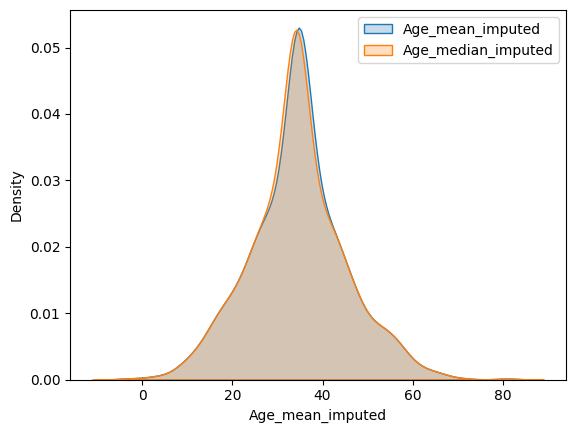

In [144]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.kdeplot(data=df, x= 'Age_mean_imputed', label = 'Age_mean_imputed', fill= True)
sns.kdeplot(data=df, x= 'Age_median_imputed', label = 'Age_median_imputed', fill= True)

plt.legend()

## ৪. কোনটি বেছে নেবেন এবং কেন? (Which one would you choose and why?)
সাধারণত Median Imputation (Age_median_imputed) বেছে নেওয়া বেশি নিরাপদ, বিশেষ করে বয়স (Age) বা স্কিউড/আউটলায়ার-সংবেদনশীল ডেটার ক্ষেত্রে—তবে চূড়ান্ত সিদ্ধান্ত নির্ভর করবে আপনার ডেটার ডিস্ট্রিবিউশনের ওপর:

কখন Median বেছে নেবেন (সাধারণত সেরা পছন্দ):

ডেটাতে Skewness (ডান বা বাম দিকে হেলে থাকা) বা Outliers (খুব বেশি বা খুব কম বয়স) থাকলে mean সহজেই সেগুলোর দিকে সরে যায়, কিন্তু median আউটলায়ার দ্বারা প্রভাবিত হয় না।

KDE প্লটে যদি দেখেন mean ইমপিউটেশনের কারণে নির্দিষ্ট কোনো জায়গায় অস্বাভাবিক তীক্ষ্ণ চূড়া (sharp spike) তৈরি হয়েছে বা ডিস্ট্রিবিউশনের আসল আকৃতি বদলে গেছে, তবে median তুলনামূলকভাবে বেশি স্থিতিশীল থাকে।

কখন Mean বেছে নেবেন:

যদি Age কলামটির ডিস্ট্রিবিউশন প্রায় Symmetric / Normal হয় এবং উল্লেখযোগ্য কোনো outlier না থাকে, তবে mean ব্যবহার করা যেতে পারে।